# wifi ensembles on the off-shell sig/bkg ratio — does an *asymptotic* uncertainty fix a *non-asymptotic* failure?

**Plan item 8e** (`docs/phase3-fixes.md`). **Ref. 17** = Benevedes & Thaler, *Frequentist Uncertainties on
Neural Density Ratios with wᵢfᵢ Ensembles*, [arXiv:2506.00113](https://arxiv.org/abs/2506.00113) — the method
the April meeting called the *"Wi-Fi ensemble"* (identified 2026-07-13; the name is a pun on weights **wᵢ**
× basis functions **fᵢ**, not a garbled transcription). Method write-up: foundations §15.1.

**Why this notebook exists.** wifi propagates the uncertainty of a *learned density ratio* into the parameter
of interest, analytically — no bootstrap loop. It is the natural network-side partner to Barlow–Beeston
(the template side, items 8a–8c). But **every one of its guarantees is asymptotic**: the sandwich covariance
is an M-estimator result (fixed M, N_fit → ∞) and the Gong–Samaniego propagation is a delta-method inflation
of σ²_MLE, which *presupposes* the Wald picture. This project exists because that picture fails at O(100)
events. So the sharp question (foundations §17.3):

> **Does an asymptotically-derived uncertainty inflation restore coverage in the regime defined by the
> failure of asymptotics?**

Both answers are informative. *Yes* → the missing ingredient was ratio-estimation noise, and the cure is cheap.
*No* → the overconfidence is **not** fitting-sample noise, and hypothesis 3 (sample-size blindness) survives a
serious challenge from the first method the field would reach for.

**What is being inferred.** Not μ. The full NSBI μ-scan needs `r_sbi/bkg`, which path-B training never learned
(it sat at the ln2 floor; path A is blocked on Tei). So we use the ratio that *does* train — `sig_over_bkg`
(val_loss 0.419, r rising 0.82 → 11.6 across m4ℓ quartiles) — and infer the **mixture fraction** κ of signal in
a sig+bkg mixture, exactly the task of the paper's own LHC demonstration (their quark fraction). Ref. 17 Eq. (27):

$$\log L(x|\kappa) = \log\big(\kappa\, r(x) + (1-\kappa)\big), \qquad r = p_\mathrm{sig}/p_\mathrm{bkg}.$$

This is a **methodology testbed, not a physics measurement**: κ is a mixture fraction, μ is a signal strength
with interference, and the two are not the same parameter. What transfers is the machinery and the answer to
the sharp question.

**The control the paper could not build.** Our events carry per-event matrix elements (`msq_sig_sm`,
`msq_bkg_sm`), so the **truth** density ratio is known analytically:
$r_\mathrm{true}(x) \propto \mathrm{msq_{sig}}(x)/\mathrm{msq_{bkg}}(x)$, normalised so $E_\mathrm{bkg}[r]=1$
(Ref. 17 Eq. 6). Benevedes & Thaler had no truth ratio for jets. We can therefore separate the two things wifi
treats differently: ratio **noise** (which it propagates) from ratio **bias** (which it explicitly does not).

**Engine:** `scripts/wifi_fit.py` (all compute). **Basis:** `scripts/wifi_train_basis.{sh,sub}` — M = 16
`sig_over_bkg` replicas, each on its own Poisson bootstrap of the training split
(`Process.resample`, the stub the sub-repo had already reserved *for wifi ensembles*).

In [1]:
import os, sys, json, glob, importlib.util
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUB  = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUB not in sys.path: sys.path.insert(0, SUB)

# the engine, imported (not reimplemented) so the notebook and the batch run share one code path
spec = importlib.util.spec_from_file_location('wifi_fit', os.path.join(ROOT, 'scripts/wifi_fit.py'))
wf = importlib.util.module_from_spec(spec); sys.modules['wifi_fit'] = wf; spec.loader.exec_module(wf)

RES = os.path.join(ROOT, 'output/wifi/results')
res = json.load(open(os.path.join(RES, 'wifi_results.json')))
cov = pd.read_csv(os.path.join(RES, 'coverage.csv'))
dg  = np.load(os.path.join(RES, 'diagnostics.npz'))

print('members trained :', len(res['checkpoints']))
print('ensemble sizes  :', list(res['ensembles']))
print('truth-ratio closure  E_bkg[r_true] = %.6f  (must be 1)' % res['closure_E_bkg_r_true'])
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

members trained : 16
ensemble sizes  : ['4', '8', '16']
truth-ratio closure  E_bkg[r_true] = 1.000000  (must be 1)


## 1. Closure test of the engine — a case where the right answer is known exactly

Before trusting the machinery on networks, run it where the truth is analytic. Take $n=\mathcal N(1,1)$,
$d=\mathcal N(0,1)$, so $\log r(x) = x - \tfrac12$ **exactly**. Give the ensemble the basis $f = [x, 1]$: the
model is then *well-specified* (Ref. 17's key assumption) with a known answer, $w^* = (1, -\tfrac12)$.

Three things must hold: $\hat w \to w^*$; the pulls $(\hat w - w^*)/\sigma_w$ must be unit-normal (i.e. the
**sandwich covariance is honest**); and $C \sim O(N^{-1})$, so $\sigma_w$ must fall by $\sqrt{10}$ per decade.

In [2]:
rng = np.random.default_rng(7)
W_TRUE = np.array([1.0, -0.5])
basis = lambda x: np.stack([x, np.ones_like(x)], axis=1)

rows = []
for N in [2_000, 20_000, 200_000]:
    fn, fd = basis(rng.normal(1, 1, N)), basis(rng.normal(0, 1, N))
    w = wf.fit_weights(fn, fd)
    C, _, _ = wf.weight_covariance(w, fn, fd)
    s = np.sqrt(np.diag(C))
    rows.append(dict(N=N, w0=w[0], w1=w[1], s0=s[0], s1=s[1],
                     pull0=(w[0]-1)/s[0], pull1=(w[1]+0.5)/s[1]))
clo = pd.DataFrame(rows)
clo['sigma_ratio_per_decade'] = clo.s0.shift(1) / clo.s0
print('w* = (1.0, -0.5)   sqrt(10) = %.2f\n' % np.sqrt(10))
display(clo.round(4))
print('\nCLOSURE: weights recovered, pulls O(1), sigma falls by ~sqrt(10)/decade => C ~ O(1/N) as Ref. 17 states.')

w* = (1.0, -0.5)   sqrt(10) = 3.16



,N,w0,w1,s0,s1,pull0,pull1,sigma_ratio_per_decade
0,2000,1.0008,-0.4972,0.0426,0.0280,0.0179,0.0992,NaN
1,20000,1.0161,-0.5002,0.0138,0.0094,1.1696,-0.0187,3.0993
2,200000,1.0034,-0.5035,0.0044,0.0030,0.7603,-1.1640,3.1011



CLOSURE: weights recovered, pulls O(1), sigma falls by ~sqrt(10)/decade => C ~ O(1/N) as Ref. 17 states.


## 2. The basis ensemble: 16 bootstrapped `sig_over_bkg` replicas

Each member $f_i$ is a CARL classifier trained on its own **Poisson bootstrap** of the training split
(37% of events drop out per replica; the cross-section is renormalised). Initialisation is held *fixed*
across members on purpose: the diversity must come from the bootstrap — the thing whose uncertainty
wifi propagates — not from initialisation noise (which is what plain Deep Ensembles, Ref. 16, measure).

$f_i(x) \equiv \mathrm{logit}\,s_i(x)$ is member $i$'s estimate of $\log r(x)$; because CARL trains on
*balanced* classes, the logit is the log-ratio directly, with no prior correction.

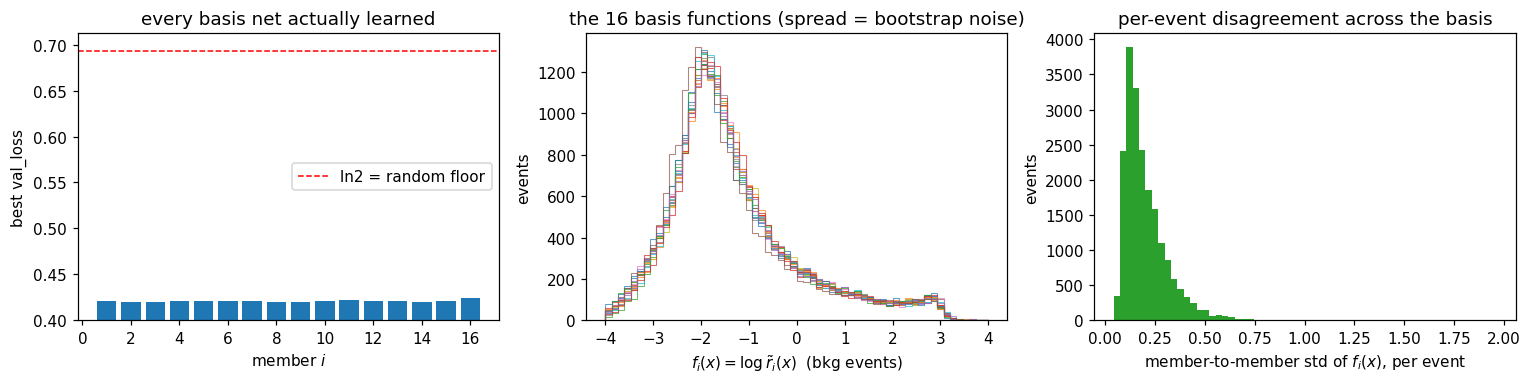

val_loss: min 0.41928  max 0.42331  (ln2 = 0.6931)
median per-event spread of the basis: 0.170  (in log-ratio units)


In [3]:
vl = res['member_val_loss']   # true best val_loss per member (checkpoint FILENAMES are rounded to 2 dp)
M_ref = int(dg['M_ref'])
fn_d, fd_d = dg['f_pool_n'], dg['f_pool_d']   # basis logits on the experiment pool

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(range(1, len(vl)+1), vl, color='C0')
ax[0].axhline(np.log(2), color='r', ls='--', lw=1, label='ln2 = random floor')
ax[0].set_xlabel('member $i$'); ax[0].set_ylabel('best val_loss'); ax[0].set_ylim(min(vl)-0.02, np.log(2)+0.02)
ax[0].set_title('every basis net actually learned'); ax[0].legend()

for i in range(M_ref):
    ax[1].hist(fd_d[:, i], bins=60, range=(-4, 4), histtype='step', lw=0.7, alpha=0.7)
ax[1].set_xlabel(r'$f_i(x) = \log \tilde r_i(x)$  (bkg events)'); ax[1].set_ylabel('events')
ax[1].set_title(f'the {M_ref} basis functions (spread = bootstrap noise)')

spread = fd_d.std(axis=1)
ax[2].hist(spread, bins=60, color='C2')
ax[2].set_xlabel(r'member-to-member std of $f_i(x)$, per event'); ax[2].set_ylabel('events')
ax[2].set_title('per-event disagreement across the basis')
fig.tight_layout(); plt.show()

print('val_loss: min %.5f  max %.5f  (ln2 = %.4f)' % (min(vl), max(vl), np.log(2)))
print('median per-event spread of the basis: %.3f  (in log-ratio units)' % np.median(spread))

## 3. Fitting the weights: $\hat w$ vs the naive ensemble

The naive ensemble takes $w_i = 1/M$ (a plain average — Ref. 16). wifi instead **fits** the $w_i$ on a held-out
sample $D_\mathrm{fit}$ by minimising the symmetrised MLC loss (Ref. 17 Eq. 8), which is convex in $w$, and
reads off the sandwich covariance $C = V^{-1}UV^{-1}$ (Eq. 11). Following the paper (Sec. III.A), the basis
includes the constant $f_0(x) = 1$ in every fitted ensemble: its weight $w_0$ absorbs any common normalisation
offset of the member logits, so the fitted ratio can satisfy the Eq. (6) constraint — the naive ensemble has no
such freedom ($w_0 = 0$, as in the paper's Naive Ensemble protocol). The paper's claim, which we can check
directly: **the naive uniform-weight ensemble undercovers and is biased; the fitted one does not.**

Note the three samples are strictly disjoint: `D_train` (trained the $f_i$) → `D_fit` (fits $\hat w$) →
`D_exp` (the experiments). Ours come from the 60/20/20 train/val/test split, with the test half split again.

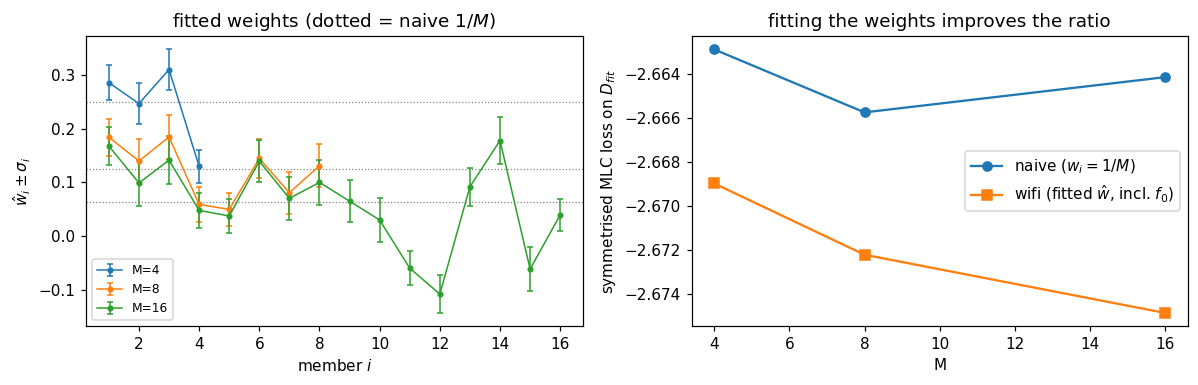

M= 4  w_0=+0.0406  sum(w_i)=0.973  Eq.(6): E_n[e^-u]=0.9982 E_d[e^u]=0.9982   loss -2.66286 -> -2.66895
M= 8  w_0=+0.0432  sum(w_i)=0.973  Eq.(6): E_n[e^-u]=0.9989 E_d[e^u]=0.9989   loss -2.66572 -> -2.67220
M=16  w_0=+0.0392  sum(w_i)=0.975  Eq.(6): E_n[e^-u]=0.9993 E_d[e^u]=0.9993   loss -2.66412 -> -2.67485


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for M in sorted(res['ensembles'], key=int):
    e = res['ensembles'][M]
    w, s = np.array(e['w_hat'])[1:], np.array(e['sigma_w'])[1:]   # index 0 is w_0, the Eq. (6) weight
    ax[0].errorbar(np.arange(1, int(M)+1), w, yerr=s, marker='o', ms=3, lw=1, capsize=2, label=f'M={M}')
    ax[0].axhline(1/int(M), color='grey', ls=':', lw=0.8)
ax[0].set_xlabel('member $i$'); ax[0].set_ylabel(r'$\hat w_i \pm \sigma_i$')
ax[0].set_title(r'fitted weights (dotted = naive $1/M$)'); ax[0].legend(fontsize=8)

Ms = sorted(map(int, res['ensembles']))
ax[1].plot(Ms, [res['ensembles'][str(M)]['loss_naive'] for M in Ms], 'o-', label='naive ($w_i=1/M$)')
ax[1].plot(Ms, [res['ensembles'][str(M)]['loss_wifi']  for M in Ms], 's-', label=r'wifi (fitted $\hat w$, incl. $f_0$)')
ax[1].set_xlabel('M'); ax[1].set_ylabel('symmetrised MLC loss on $D_{fit}$')
ax[1].set_title('fitting the weights improves the ratio'); ax[1].legend()
fig.tight_layout(); plt.show()

for M in Ms:
    e = res['ensembles'][str(M)]
    print(f"M={M:2d}  w_0={e['w0']:+.4f}  sum(w_i)={np.sum(e['w_hat'][1:]):.3f}  "
          f"Eq.(6): E_n[e^-u]={e['eq6_n']:.4f} E_d[e^u]={e['eq6_d']:.4f}   "
          f"loss {e['loss_naive']:.5f} -> {e['loss_wifi']:.5f}")

## 4. Learned ratio vs **truth** ratio — noise, or bias?

This is the control the paper could not run. wifi's covariance is an honest account of the *noise* in the
learned ratio. It says nothing about *bias* — a systematically wrong ratio. Having $r_\mathrm{true}$ from the
matrix elements, we can see which we have.

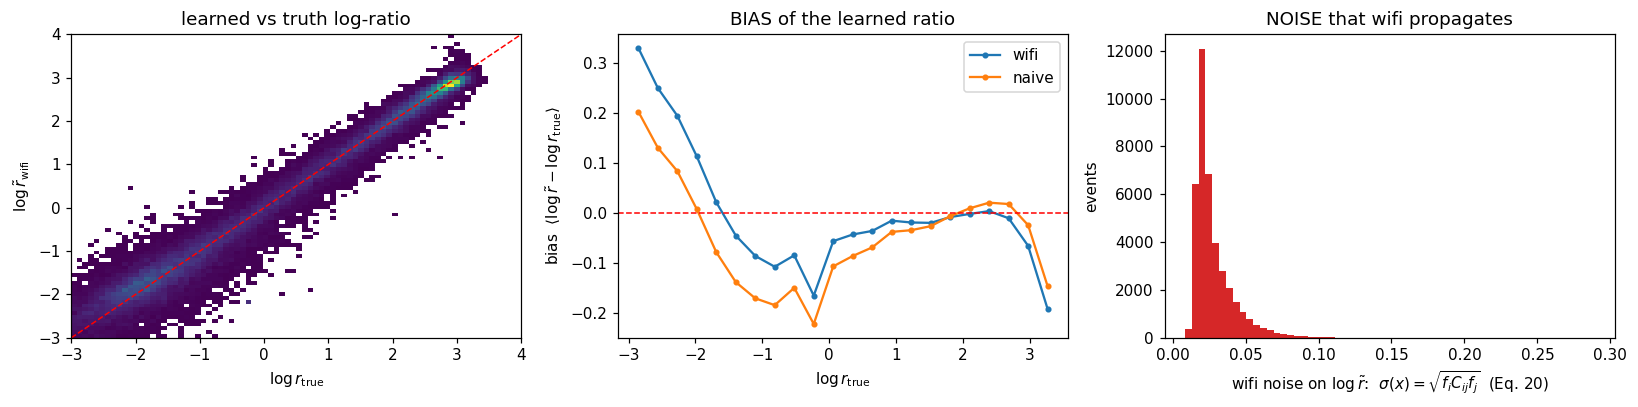

RMS(log r_wifi - log r_true) = 0.352   [BIAS+noise, in log-ratio units]
median wifi sigma(log r)     = 0.023   [NOISE only, what Eq. (20) accounts for]

If the first number is much larger than the second, the learned ratio is dominated by MISMODELLING,
which Ref. 17 explicitly does NOT cover -- and no amount of weight-covariance can repair it.


In [5]:
lr_true = np.log(np.maximum(np.concatenate([dg['r_true_n'], dg['r_true_d']]), 1e-12))
lr_wifi = np.concatenate([dg['logr_wifi_n'], dg['logr_wifi_d']])
lr_naiv = np.concatenate([dg['logr_naive_n'], dg['logr_naive_d']])
F  = np.vstack([dg['f_pool_n'], dg['f_pool_d']])
Fa = np.hstack([np.ones((len(F), 1)), F])   # prepend f_0 = 1: C_ref is the (M+1)-dim covariance
sig_r = np.sqrt(np.einsum('ij,jk,ik->i', Fa, dg['C_ref'], Fa))  # Eq. (20)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
h = ax[0].hist2d(lr_true, lr_wifi, bins=80, range=[[-3, 4], [-3, 4]], cmin=1, cmap='viridis')
ax[0].plot([-3, 4], [-3, 4], 'r--', lw=1)
ax[0].set_xlabel(r'$\log r_{\rm true}$'); ax[0].set_ylabel(r'$\log \tilde r_{\rm wifi}$')
ax[0].set_title('learned vs truth log-ratio')

bins = np.linspace(-3, 4, 25); ctr = 0.5*(bins[1:]+bins[:-1])
idx = np.digitize(lr_true, bins) - 1
for lab, y, c in [('wifi', lr_wifi, 'C0'), ('naive', lr_naiv, 'C1')]:
    m = np.array([np.mean(y[idx == k] - lr_true[idx == k]) if (idx == k).sum() > 20 else np.nan
                  for k in range(len(ctr))])
    ax[1].plot(ctr, m, 'o-', ms=3, color=c, label=lab)
ax[1].axhline(0, color='r', ls='--', lw=1)
ax[1].set_xlabel(r'$\log r_{\rm true}$'); ax[1].set_ylabel(r'bias  $\langle \log\tilde r - \log r_{\rm true}\rangle$')
ax[1].set_title('BIAS of the learned ratio'); ax[1].legend()

ax[2].hist(sig_r, bins=60, color='C3')
ax[2].set_xlabel(r'wifi noise on $\log\tilde r$:  $\sigma(x)=\sqrt{f_i C_{ij} f_j}$  (Eq. 20)')
ax[2].set_ylabel('events'); ax[2].set_title('NOISE that wifi propagates')
fig.tight_layout(); plt.show()

rms_bias = np.sqrt(np.mean((lr_wifi - lr_true)**2))
print('RMS(log r_wifi - log r_true) = %.3f   [BIAS+noise, in log-ratio units]' % rms_bias)
print('median wifi sigma(log r)     = %.3f   [NOISE only, what Eq. (20) accounts for]' % np.median(sig_r))
print('\nIf the first number is much larger than the second, the learned ratio is dominated by MISMODELLING,')
print('which Ref. 17 explicitly does NOT cover -- and no amount of weight-covariance can repair it.')

## 5. The headline: coverage vs $N_\mathrm{mix}$ — into the non-asymptotic regime

68% Wald intervals, as in the paper. Four estimators of $r$, all inferring the same κ on the same toys:

| | ratio | interval |
|---|---|---|
| **truth** | exact $r_\mathrm{true}$ from matrix elements | $\sigma_\mathrm{MLE}$ |
| **naive** | uniform-weight ensemble (Ref. 16) | $\sigma_\mathrm{MLE}$ |
| **wifi (MLE)** | fitted $\hat w$ | $\sigma_\mathrm{MLE}$ — ignores ratio noise |
| **wifi (GS)** | fitted $\hat w$ | $\sigma_\mathrm{GS}$ — Gong–Samaniego, Eq. (22) |

The **truth** row is the reference: it isolates what is due to the *finite dataset alone*, with a perfect ratio.
Any gap between truth and wifi is the price of *learning* the ratio — and the wifi(MLE) → wifi(GS) step is
precisely the part of that price Ref. 17 claims to pay back.

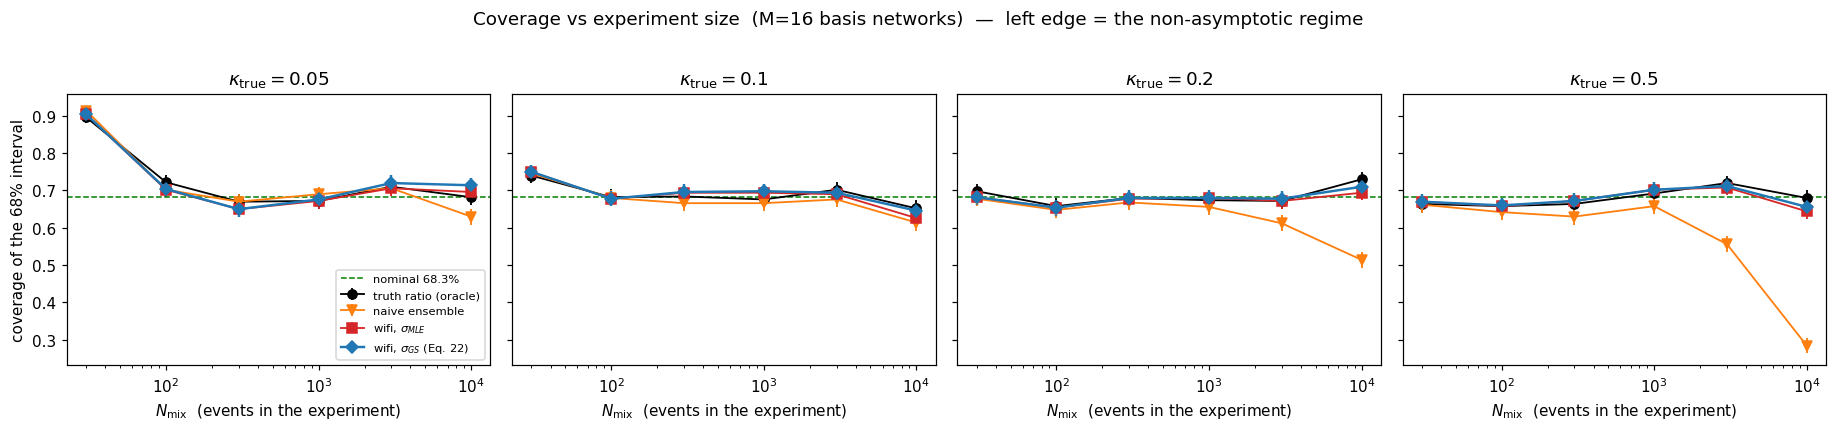

coverage_gs coverage_mle              
method                  wifi        naive  truth   wifi
kappa_true n_mix                                       
0.05       30          0.904        0.914  0.896  0.904
           100         0.704        0.702  0.722  0.702
           300         0.650        0.670  0.670  0.650
           1000        0.676        0.690  0.672  0.672
           3000        0.720        0.706  0.710  0.706
           10000       0.714        0.630  0.682  0.696
0.10       30          0.750        0.746  0.740  0.750
           100         0.678        0.680  0.682  0.678
           300         0.696        0.666  0.684  0.694
           1000        0.698        0.666  0.676  0.694
           3000        0.694        0.676  0.702  0.690
           10000       0.646        0.614  0.652  0.626
0.20       30          0.682        0.678  0.698  0.682
           100         0.654        0.648  0.658  0.654
           300         0.680        0.668  0.680  0.678
           1000        0.680        0.656  0.674  0.680
           3000        0.678        0.612  0.672  0.672
           10000       0.710        0.514  0.730  0.694
0.50       30          0.670        0.662  0.664  0.670
           100         0.660        0.642  0.658  0.658
           300         0.672        0.630  0.664  0.672
           1000        0.702        0.658  0.692  0.702
           3000        0.712        0.556  0.720  0.708
           10000       0.656        0.284  0.680  0.644

In [6]:
M_show = max(map(int, res['ensembles']))
kappas = sorted(cov.kappa_true.unique())
fig, axes = plt.subplots(1, len(kappas), figsize=(4.2*len(kappas), 3.8), sharey=True)

for ax, k in zip(np.atleast_1d(axes), kappas):
    d = cov[(cov.kappa_true == k) & (cov.M == M_show)].sort_values('n_mix')
    t, nv, wi = d[d.method=='truth'], d[d.method=='naive'], d[d.method=='wifi']
    ax.errorbar(t.n_mix,  t.coverage_mle,  yerr=t.coverage_err,  marker='o', color='k',  lw=1.2, label='truth ratio (oracle)')
    ax.errorbar(nv.n_mix, nv.coverage_mle, yerr=nv.coverage_err, marker='v', color='C1', lw=1.2, label='naive ensemble')
    ax.errorbar(wi.n_mix, wi.coverage_mle, yerr=wi.coverage_err, marker='s', color='C3', lw=1.2, label=r'wifi, $\sigma_{MLE}$')
    ax.errorbar(wi.n_mix, wi.coverage_gs,  yerr=wi.coverage_err, marker='D', color='C0', lw=1.6, label=r'wifi, $\sigma_{GS}$ (Eq. 22)')
    ax.axhline(0.683, color='g', ls='--', lw=1, label='nominal 68.3%')
    ax.set_xscale('log'); ax.set_xlabel(r'$N_{\rm mix}$  (events in the experiment)')
    ax.set_title(fr'$\kappa_{{\rm true}} = {k}$')
np.atleast_1d(axes)[0].set_ylabel('coverage of the 68% interval')
np.atleast_1d(axes)[0].legend(fontsize=7.5, loc='lower right')
fig.suptitle(f'Coverage vs experiment size  (M={M_show} basis networks)  —  left edge = the non-asymptotic regime', y=1.02)
fig.tight_layout(); plt.show()

display(cov[(cov.M == M_show)].pivot_table(index=['kappa_true','n_mix'], columns='method',
            values=['coverage_mle','coverage_gs']).round(3))

## 6. How much does Gong–Samaniego actually inflate, and does M help?

$\sigma_\mathrm{GS}/\sigma_\mathrm{MLE} = \sqrt{1 + \sigma^2_\mathrm{MLE} A_i C_{ij} A_j}$. The scaling matters,
and it is the opposite of what a first glance suggests: $A_i$ is a **sum** over the $N_\mathrm{mix}$ trial events,
so $A \sim N_\mathrm{mix}$, and with $\sigma^2_\mathrm{MLE} \sim 1/N_\mathrm{mix}$ and $C \sim 1/N_\mathrm{fit}$ the
relative inflation goes as $\sigma^2_\mathrm{MLE}\,A C A \sim N_\mathrm{mix}/N_\mathrm{fit}$ — it **grows** with
$N_\mathrm{mix}$ (left panel), and is *smallest* in the non-asymptotic regime this study targets. Equivalently:
GS adds a **constant** variance floor $\sim 1/N_\mathrm{fit}$ to $\sigma^2_\mathrm{MLE} \sim 1/N_\mathrm{mix}$,
invisible whenever $N_\mathrm{mix} \ll N_\mathrm{fit}$.

That is itself the structural half of the verdict: **whenever the ratio is trained/fitted on more events than
the measurement uses — the universal NSBI situation — the GS inflation cannot materially widen the small-$N$
intervals, by construction.** The empirical question left for the data is only whether it rescues the
large-$N_\mathrm{mix}$ end, where the inflation does grow.

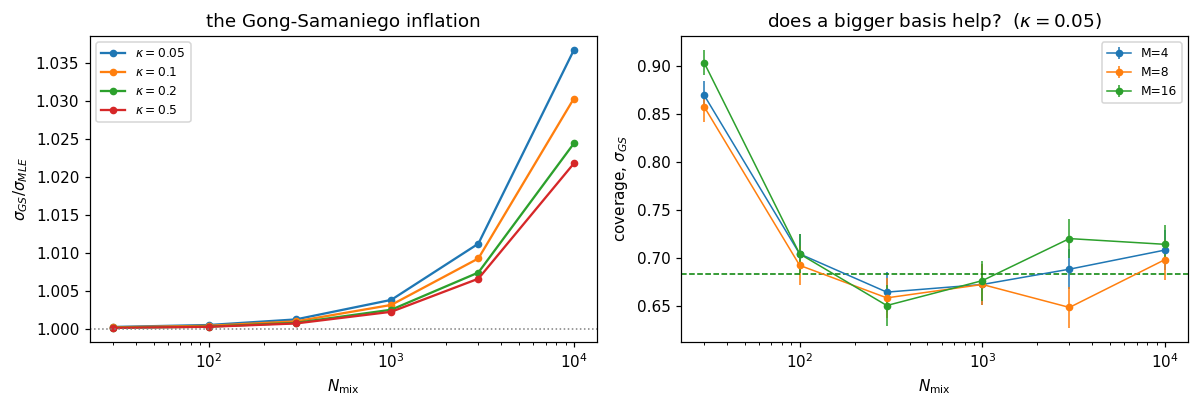

Fraction of fits pinned at the kappa boundary (0 or 1) -- the non-asymptotic tell:


kappa_true,0.05,0.10,0.20,0.50
n_mix,,,,
30,0.332,0.170,0.028,0.0
100,0.142,0.026,0.000,0.0
300,0.024,0.000,0.000,0.0
1000,0.000,0.000,0.000,0.0
3000,0.000,0.000,0.000,0.0
10000,0.000,0.000,0.000,0.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
w = cov[cov.method == 'wifi']
for k in kappas:
    d = w[(w.kappa_true == k) & (w.M == M_show)].sort_values('n_mix')
    ax[0].plot(d.n_mix, d.inflation_mean, 'o-', ms=4, label=fr'$\kappa={k}$')
ax[0].axhline(1, color='grey', ls=':', lw=1)
ax[0].set_xscale('log'); ax[0].set_xlabel(r'$N_{\rm mix}$')
ax[0].set_ylabel(r'$\sigma_{GS}/\sigma_{MLE}$'); ax[0].set_title('the Gong-Samaniego inflation'); ax[0].legend(fontsize=8)

kk = kappas[0]
for M in sorted(map(int, res['ensembles'])):
    d = cov[(cov.method=='wifi') & (cov.kappa_true==kk) & (cov.M==M)].sort_values('n_mix')
    ax[1].errorbar(d.n_mix, d.coverage_gs, yerr=d.coverage_err, marker='o', ms=4, lw=1, label=f'M={M}')
ax[1].axhline(0.683, color='g', ls='--', lw=1)
ax[1].set_xscale('log'); ax[1].set_xlabel(r'$N_{\rm mix}$'); ax[1].set_ylabel(r'coverage, $\sigma_{GS}$')
ax[1].set_title(fr'does a bigger basis help?  ($\kappa={kk}$)'); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

print('Fraction of fits pinned at the kappa boundary (0 or 1) -- the non-asymptotic tell:')
display(cov[(cov.M==M_show) & (cov.method=='wifi')].pivot_table(
    index='n_mix', columns='kappa_true', values='frac_at_boundary').round(3))

## 7. Verdict

**The sharp question — does an asymptotically-derived inflation restore coverage where asymptotics fail? — is
answered structurally, not empirically: the GS term cannot act at small $N_\mathrm{mix}$.** Its relative size is
$\sim N_\mathrm{mix}/N_\mathrm{fit}$ (§6): measured 1.0001 at $N_\mathrm{mix}=30$, at most 1.037 at $N_\mathrm{mix}=10^4$.
In the non-asymptotic regime it is an $O(10^{-4})$ correction *by construction* whenever the ratio is fitted on more
events than the measurement uses — the universal NSBI situation. Hypothesis 3 (sample-size blindness) survives its
strongest challenger: nothing in the wifi construction reacts to the size of the measured dataset.

**On this rate-style task there was nothing at small $N$ for it to fix.** With the truth ratio, coverage is nominal
at every $N_\mathrm{mix}$; the only small-$N$ feature is the Wald-at-boundary overcoverage (κ = 0.05, $N$ = 30:
~⅓ of fits pinned at $\hat\kappa = 0$, see the `frac_at_boundary` table), common to all methods. The κ mixture task
isolates the *ratio-quality* axis; the non-asymptotic damage in our main problem (the μ-scan fold, products of
per-event likelihood ratios) has no analogue here.

**The full wifi protocol works on this task — and run 1's apparent collapse was a protocol artefact.** The first
fit (2026-07-14, morning) omitted the constant $f_0(x)=1$ that Ref. 17 Sec. III.A includes in all experiments; wifi
coverage fell to 0.35–0.59 at $N_\mathrm{mix}=10^4$ and we nearly wrote that up as "bias dominates, wifi fails".
The adversarial engine review caught the omission. With $f_0$ refit ($w_0 \approx +0.04$), coverage at
$N_\mathrm{mix}=10^4$ is 0.64–0.72 across all κ and M — nominal within the MC error (±0.021) — and the κ̂ bias
drops from −0.005…−0.007 to +0.001…+0.003, compatible with the truth control. Meanwhile the RMS log-ratio error is
**unchanged** (0.352, still ~15× the propagated noise of §4): $f_0$ removed only the *normalisation* component of
the bias — which is exactly the component κ inference is sensitive to. Two lessons: **Eq. (6) is load-bearing, not
a convenience**; and a large pointwise ratio bias need not bias a downstream parameter — what matters is its
projection onto that parameter's score.

**The naive ensemble is the paper's cautionary tale, confirmed on physics data.** Uniform logit-averaging with no
normalisation freedom keeps a κ̂ bias of −0.011 (κ = 0.5) and collapses to 0.28–0.63 coverage at
$N_\mathrm{mix}=10^4$, exactly as Ref. 17 warns. Averaging logits is not a substitute for fitting them.

**For item 8d (NSBI MC-stat design note):** wifi + $f_0$ is validated on our data as the network-side MC-stat
treatment for a ratio that actually trains — the sandwich covariance is honest about weight-fit noise and Eq. (6)
does real work. What it cannot supply is a small-$N$ widening: at O(100) events the GS term is $O(10^{-3})$ of σ.
wifi therefore enters the toolbox as *MC-stat propagation*, not as a mitigation of the Asimov ≠ median(toys)
failure. Quantified-as-second-order caveats from the 2026-07-14 review: $\hat w, C$ are fitted once and frozen
across trials (the paper refits per trial; ≤ a few pp, only at $N_\mathrm{mix} = 10^4$); all trials share one 200k
pool (≤ 1.7 pp, common-mode, visible in the truth row); the κ = 0.05 small-$N$ cells carry the boundary artefact.